In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries loaded!")

Libraries loaded!


In [7]:
# Load dataset
df = pd.read_csv('/mnt/software_requirements_cleaned.csv')

print("Shape:", df.shape)
print(df.head())

# Define input (X) and output (y)
X = df[['Type_encoded']]           # input feature
y = df['requirement_length']       # what we're predicting

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Shape: (527, 5)
  Type                                        Description  Type_encoded  \
0   PE  The system shall refresh the display every 60 ...             7   
1   LF  The application shall match the color of the s...             4   
2   US  If projected  the data must be readable.  On a...            11   
3    A  The product shall be available during normal b...             0   
4   US  If projected  the data must be understandable....            11   

   requirement_length  requirement_length_scaled  
0                  54                  -1.033178  
1                  96                  -0.338042  
2                 159                   0.704661  
3                 196                   1.317043  
4                 203                   1.432898  

X shape: (527, 1)
y shape: (527,)


In [8]:
# Split data — 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])

Training size: 421
Testing size: 106


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Coefficient (slope):', round(model.coef_[0], 4))
print('Intercept:', round(model.intercept_, 4))
print()
print('This means: for every 1 unit increase in Type_encoded,')
print(f'requirement_length changes by {round(model.coef_[0], 2)} characters')

Coefficient (slope): 2.5741
Intercept: 93.4003

This means: for every 1 unit increase in Type_encoded,
requirement_length changes by 2.57 characters


In [10]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

print('=== Model Evaluation (Simple Regression) ===')
print(f'MAE  (Mean Absolute Error):  {round(mae, 2)}')
print(f'MSE  (Mean Squared Error):   {round(mse, 2)}')
print(f'R²   (R-squared Score):      {round(r2, 4)}')
print()
print('Interpretation:')
print(f'On average, predictions are off by {round(mae, 1)} characters')
print(f'The model explains {round(r2*100, 2)}% of variance in requirement length')

=== Model Evaluation (Simple Regression) ===
MAE  (Mean Absolute Error):  30.41
MSE  (Mean Squared Error):   1774.39
R²   (R-squared Score):      0.1011

Interpretation:
On average, predictions are off by 30.4 characters
The model explains 10.11% of variance in requirement length


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


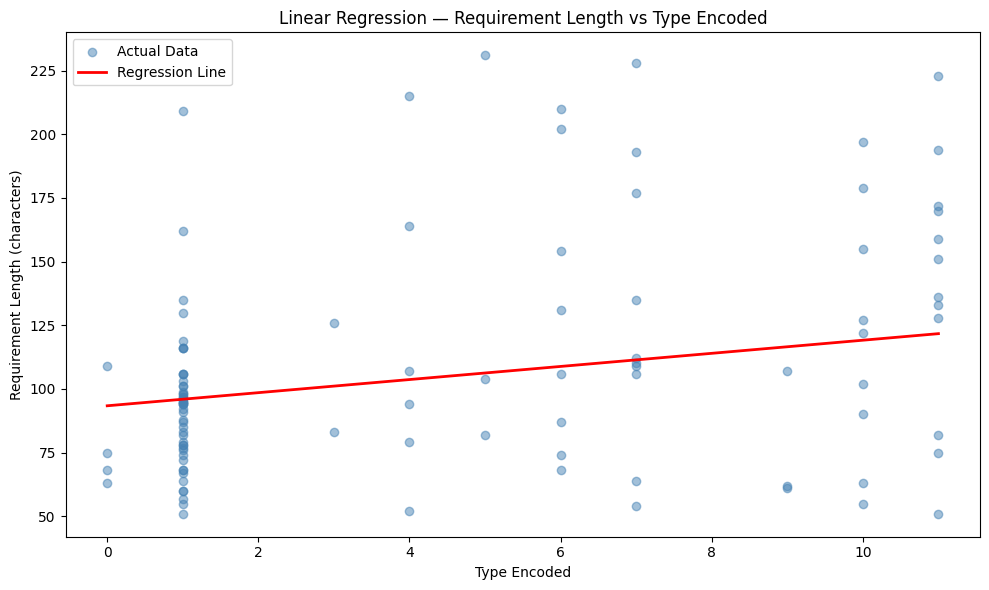

Regression line plot saved!


In [11]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test, y_test, color='steelblue', alpha=0.5, label='Actual Data')

X_line = np.linspace(X['Type_encoded'].min(), X['Type_encoded'].max(), 100).reshape(-1, 1)
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='Regression Line')

plt.title('Linear Regression — Requirement Length vs Type Encoded')
plt.xlabel('Type Encoded')
plt.ylabel('Requirement Length (characters)')
plt.legend()
plt.tight_layout()
plt.savefig('regression_line.png')
plt.show()
print('Regression line plot saved!')

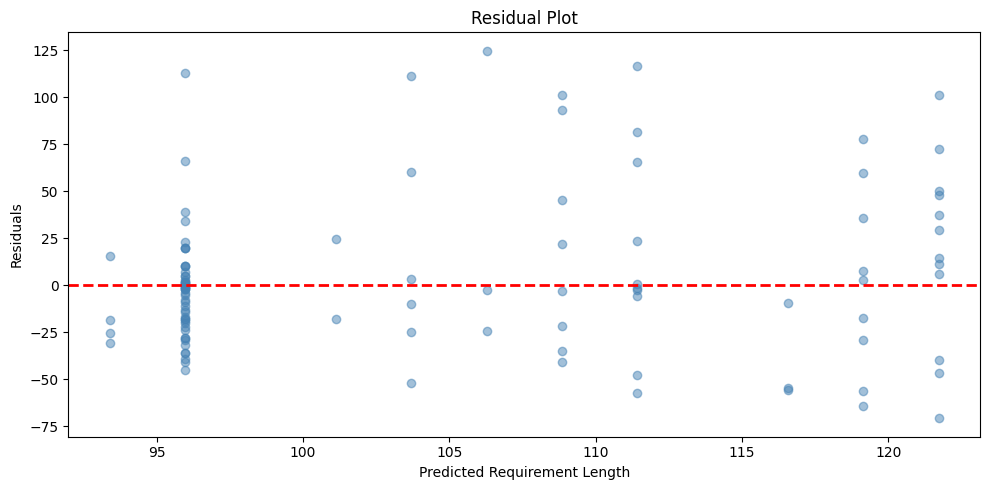

Residual plot saved!


In [13]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuals, color='steelblue', alpha=0.5)
plt.axhline(y=0, color='red', linewidth=2, linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Predicted Requirement Length')
plt.ylabel('Residuals')
plt.tight_layout()
plt.savefig('residual_plot.png')
plt.show()
print('Residual plot saved!')

In [14]:
# Calculate word_count in memory — CSV is not modified
df['word_count'] = df['Description'].apply(lambda x: len(str(x).split()))

# Two inputs now
X_multi = df[['Type_encoded', 'word_count']]
y_multi  = df['requirement_length']

# Split
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

# Train
model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

# Evaluate
y_pred_m = model_multi.predict(X_test_m)

print('=== Multiple Regression Evaluation ===')
print(f'MAE:  {round(mean_absolute_error(y_test_m, y_pred_m), 2)}')
print(f'MSE:  {round(mean_squared_error(y_test_m, y_pred_m), 2)}')
print(f'R²:   {round(r2_score(y_test_m, y_pred_m), 4)}')
print()
print('Coefficients:')
for feature, coef in zip(X_multi.columns, model_multi.coef_):
    print(f'  {feature}: {round(coef, 4)}')
print()
print('Interpretation:')
print('Adding word_count as a second feature dramatically improves R²')
print('from 0.1011 (simple) to 0.9403 (multiple) — word count is a strong predictor')

=== Multiple Regression Evaluation ===
MAE:  8.1
MSE:  117.83
R²:   0.9403

Coefficients:
  Type_encoded: 0.3045
  word_count: 5.7016

Interpretation:
Adding word_count as a second feature dramatically improves R²
from 0.1011 (simple) to 0.9403 (multiple) — word count is a strong predictor


In [15]:
from google.colab import files
files.download('regression_line.png')
files.download('residual_plot.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>